# Comparing tTEM with tTEM

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from em1d.experiment import *
from em1d.inversion import *

In [2]:
gpu = torch.device('cpu')
cmdl = FewLayerModel.starting_model(3)

In [3]:
tx = Loop.square(3)
rx = Receiver(x=13)

In [4]:
tgates = torch.logspace(-5, -3, 21)

recfilters = FilterChain([
    ButterworthFilter(6.79e5),
])

device = torch.device('cpu')
fwr = Forward(tx, rx, tgates, Waveform.example(), recfilters)

/home/matt/repositories/em1d/src/em1d/experiment/experiment.py:109: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return tc.tensor(overall_min)


In [5]:
res = np.array([10, 200, 20])
thick1 = np.linspace(0.1, 5, 25)

In [6]:
sigma = torch.from_numpy(1./res)
thick = torch.tensor([5, 10])
data = fwr(sigma, thick)

In [7]:
thick_stack = np.vstack([thick1, np.ones_like(thick1)*10])
sigma = torch.from_numpy(1./res)[:, None]
thick = torch.from_numpy(thick_stack)

RuntimeError: shape '[21, 4]' is invalid for input of size 420

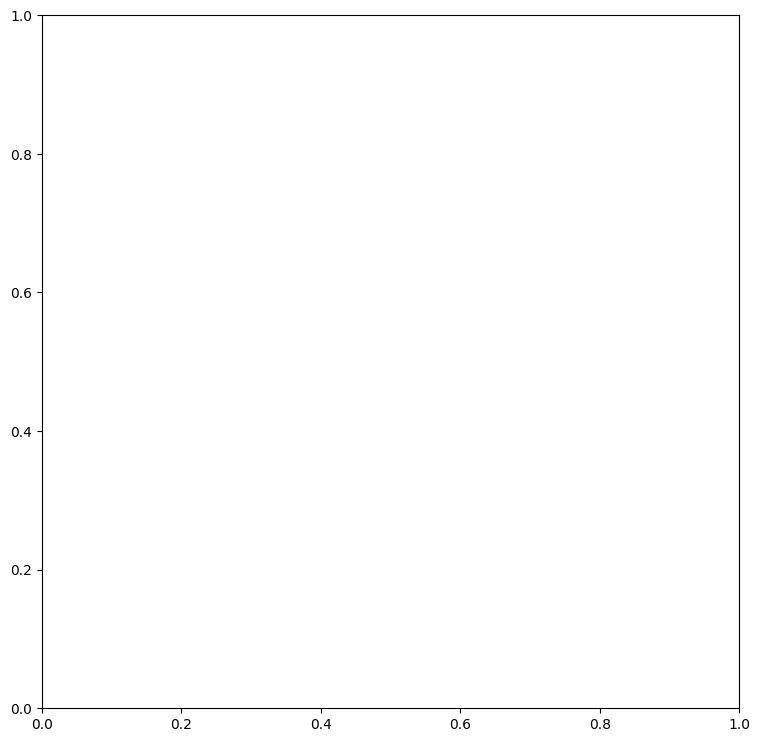

In [8]:
cm = plt.get_cmap('Spectral')

fig,axs = plt.subplots(1,1, sharex=True, figsize=(9,9))

for i,thk in enumerate(thick1):
    sigma = torch.from_numpy(1./res)
    thick = torch.tensor([thk, 10])
    dbdt = fwr(sigma, thick)
    dbdt_err = compute_relstd(tgates, dbdt, moment=3*9)

    m_true = FewLayerModel(sigma, thick, device=gpu)


    inv = Inversion(dbdt, dbdt*dbdt_err, m_true, fwr)
    inv.plot_sensitivity_analysis(ax=axs, x_offset=i*2, cbar=i==2)

    cmd_smooth = SmoothModel.starting_model(31, device=gpu)    
    dbdt_with_noise = dbdt + torch.clamp(torch.randn(len(dbdt), device=gpu), -1,1)*dbdt*dbdt_err/2

    inv2 = Inversion(dbdt_with_noise, dbdt*dbdt_err, cmd_smooth, fwr, logger=print)
    rmod = inv2.invert(smoothness=10, iter_cap=20)
    
axs.set_ylim(5,0)

plt.tight_layout()